# Business prediction requirements and target feasibility

Assess existing evidence before preparation or training. The five suggested business uses are examples within broader capability families. This notebook does not implement a question interpreter, prediction engine, automatic model selector, target builder or training pipeline. Original sources and prior deliverables remain unchanged.

## Evidence, task boundary and assessment cutoff

Review all 20 tables, 521 columns, 37 date fields and 135 identifier candidates through the validated inventory, quality and relationship evidence. New tables are documentation and audit evidence, not target series or features. The as-of date is 2026-11-02; source event timezone, actual/planned semantics and extraction closure remain unapproved.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "dataset").is_dir()
sys.path.insert(0, str(ROOT / "src" / "data"))
from assess_prediction_feasibility import FeasibilityAssessment
assessment = FeasibilityAssessment(ROOT)
print("Interpreter:", sys.executable)
print("Project:", ROOT)

Interpreter: D:\Aroha_Files\NOP_Project\.venv\Scripts\python.exe
Project: D:\Aroha_Files\NOP_Project


In [2]:
results = assessment.run()
validation = json.loads((assessment.out / "feasibility_validation.json").read_text(encoding="utf-8"))
display(pd.Series({k: validation[k] for k in ["source_files", "source_tables", "schema_columns", "date_fields", "identifier_candidates", "illustrative_assessments", "capability_families", "all_inputs_unchanged"]}, name="Assessment scope"))

Assessment complete: 20 tables; 13 examples; 25 verified workbook sheets; prior inputs preserved.


source_files                  17
source_tables                 20
schema_columns               521
date_fields                   37
identifier_candidates        135
illustrative_assessments      13
capability_families           10
all_inputs_unchanged        True
Name: Assessment scope, dtype: object

## Source meanings, identifiers and granularity

A line is not a document, an update timestamp is not transaction history, a current master is not an eligibility panel and a grouped inventory report is not a regular snapshot series. Reused SO numbers and missing line IDs limit target counts. Independently reread small order/invoice sources validate the prior within-key variation evidence.

In [3]:
display(results["source_grain_evidence"])
display(results["independent_grain_probes"])
display(results["source_authority"])

,table,file,worksheet,row_count,nonempty_rows,empty_rows,column_count,candidate_business_entity,candidate_record_grain,evidence,business_confirmation
0,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 1.xlsx,Sheet1,40,40,0,35,Customer / business partner,Customer-master record candidate; repeated cod...,Customer code: 40 distinct; 0 excess repeated ...,"Business owner must confirm entity scope, extr..."
1,Customer Master Report 2.xlsx :: Sheet1,Customer Master Report 2.xlsx,Sheet1,5015,5012,3,35,Customer / business partner,Customer-master record candidate; repeated cod...,Customer code: 4997 distinct; 15 excess repeat...,"Business owner must confirm entity scope, extr..."
2,Exchange Rate 1.xlsx :: INR to JPY,Exchange Rate 1.xlsx,INR to JPY,7,7,0,7,Currency rate period,Monthly currency-pair period record candidate,Explicit SYNTHETIC DATA title; monthly period ...,"Business owner must confirm entity scope, extr..."
3,Exchange Rate.xlsx :: INR to JPY,Exchange Rate.xlsx,INR to JPY,22,22,0,7,Currency rate period,Monthly currency-pair period record candidate,Explicit SYNTHETIC DATA title; monthly period ...,"Business owner must confirm entity scope, extr..."
4,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),GSTR1_Credit_Debit_Note 1.csv,(CSV table),6,6,0,64,GST credit/debit adjustment,Credit/debit reporting detail candidate; obser...,"Credit/debit type, note series and original in...","Business owner must confirm entity scope, extr..."
5,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),GSTR1_Credit_Debit_Note 2.csv,(CSV table),279,276,3,64,GST credit/debit adjustment,Credit/debit reporting detail candidate; obser...,"Credit/debit type, note series and original in...","Business owner must confirm entity scope, extr..."
6,GSTR1_Invoice.csv :: (CSV table),GSTR1_Invoice.csv,(CSV table),337,337,0,68,GST invoice reporting detail,"Tax reporting line candidate, scoped invoice n...",Series/prefix/suffix and raw invoice number; i...,"Business owner must confirm entity scope, extr..."
7,Inventory Audit Report as on 200327.xlsx :: Sh...,Inventory Audit Report as on 200327.xlsx,Sheet1,108129,108124,5,13,Inventory grouped audit / movement,"Mixed item labels, opening-balance lines and m...",5010 item-labelled rows; 5010 opening balance ...,"Business owner must confirm entity scope, extr..."
8,Inventory Audit Report as on 200926 1.xlsx :: ...,Inventory Audit Report as on 200926 1.xlsx,Sheet1,162,162,0,13,Inventory grouped audit / movement,"Mixed item labels, opening-balance lines and m...",52 item-labelled rows; 52 opening balance rows...,"Business owner must confirm entity scope, extr..."
9,Inventory Audit Report as on 200926.xlsx :: Sh...,Inventory Audit Report as on 200926.xlsx,Sheet1,162,162,0,13,Inventory grouped audit / movement,"Mixed item labels, opening-balance lines and m...",52 item-labelled rows; 52 opening balance rows...,"Business owner must confirm entity scope, extr..."


,file,worksheet,raw_document_key,attribute,source_rows,document_groups,groups_with_multiple_raw_attribute_values,interpretation
0,Sales Order Report 1.xlsx,Sheet1,SO No,Customer Code,1098,299,275,"Confirmed raw variation; reused scope, formatt..."
1,Sales Order Report 1.xlsx,Sheet1,SO No,Customer Ref No,1098,299,278,"Confirmed raw variation; reused scope, formatt..."
2,Sales Order Report 1.xlsx,Sheet1,SO No,Posting Date,1098,299,278,"Confirmed raw variation; reused scope, formatt..."
3,Sales Order Report 1.xlsx,Sheet1,SO No,Status,1098,299,46,"Confirmed raw variation; reused scope, formatt..."
4,Sales Invoice Details.xlsx,Sheet1,Invoice Num,Customer Billing Name,337,234,0,"Confirmed raw variation; reused scope, formatt..."
5,Sales Invoice Details.xlsx,Sheet1,Invoice Num,Invoice Date,337,234,0,"Confirmed raw variation; reused scope, formatt..."
6,Sales Invoice Details.xlsx,Sheet1,Invoice Num,Invoice Total Include GST,337,234,0,"Confirmed raw variation; reused scope, formatt..."
7,Sales Invoice Details.xlsx,Sheet1,Invoice Num,SO Num,337,234,0,"Confirmed raw variation; reused scope, formatt..."


,domain,candidate_source,evidence,decision
0,Customers,Customer Master Reports; Customer list only as...,Customer attributes and business codes; comple...,No authoritative source confirmed; versions co...
1,Products,Item Master Lists; PTC_NOPI/PCT_NOPJ classific...,SAP item and foreign product namespaces; class...,No authoritative version/crosswalk confirmed; ...
2,Orders,Sales Order Report exports,"SO references, customer/product, quantities an...","Potential order detail fact sources; scope, hi..."
3,Sales/invoices,Sales Invoice Details; GST invoice as reconcil...,Invoice line measures and scoped GST document ...,Keep sources separate; do not stack overlappin...
4,GST/adjustments,GSTR1 Invoice and Credit/Debit Note CSVs,"Reporting fields, series, tax amounts and orig...",Candidate tax/adjustment evidence only; filing...
5,Inventory,Three inventory audit exports,"Grouped item labels, opening balances, documen...",Require approved grouped-layout reconstruction...
6,Currency/country/service,Synthetic rate periods; country reference; G/S...,Two explicit synthetic rate titles; multilingu...,No production FX authority or independent serv...


## Historical coverage and observation suitability

Calendar-resolved values may depend on a century convention. The conservative view requires a native/full-year one-interpretation timestamp at or before the cutoff. Neither proves actual event meaning, production authenticity, information availability or complete periods. Only previously explicit ISO date evidence is read; ambiguous source dates remain raw. Date-cell counts and buckets below are coverage diagnostics, not business target values.

In [4]:
coverage = results["historical_date_coverage"]
display(coverage[["file", "worksheet", "column", "nonblank_date_cells", "ambiguous_day_month_cells", "possible_serial_cells", "century_dependent_cells_including_ambiguous", "strict_partial_history_min", "strict_partial_history_max", "distinct_observed_days_asof", "distinct_iso_weeks_asof", "distinct_observed_months_asof", "calendar_resolved_beyond_asof"]])

,file,worksheet,column,nonblank_date_cells,ambiguous_day_month_cells,possible_serial_cells,century_dependent_cells_including_ambiguous,strict_partial_history_min,strict_partial_history_max,distinct_observed_days_asof,distinct_iso_weeks_asof,distinct_observed_months_asof,calendar_resolved_beyond_asof
0,Exchange Rate 1.xlsx,INR to JPY,Rate Month,7,0,0,2,,,0,0,0,0
1,Exchange Rate 1.xlsx,INR to JPY,Start Date,7,0,2,0,2026-08-21,2026-09-21,2,2,2,3
2,Exchange Rate 1.xlsx,INR to JPY,End Date,7,0,1,0,2026-09-20,2026-10-20,2,2,2,4
3,Exchange Rate.xlsx,INR to JPY,Rate Month,22,0,0,22,,,0,0,0,0
4,Exchange Rate.xlsx,INR to JPY,Start Date,22,0,0,0,2024-12-21,2026-09-21,22,22,22,0
5,Exchange Rate.xlsx,INR to JPY,End Date,22,0,0,0,2025-01-20,2026-10-20,22,22,22,0
6,GSTR1_Credit_Debit_Note 1.csv,(CSV table),CreditDebitNote_Date,6,3,0,0,2026-01-29,2026-06-24,3,3,3,0
7,GSTR1_Credit_Debit_Note 1.csv,(CSV table),Invoice_Date,6,3,0,0,2026-01-18,2026-03-30,2,2,2,0
8,GSTR1_Credit_Debit_Note 1.csv,(CSV table),Original_CreditDebitNote_Date,0,0,0,0,,,0,0,0,0
9,GSTR1_Credit_Debit_Note 1.csv,(CSV table),Revision_Month,6,0,0,0,,,0,0,0,0


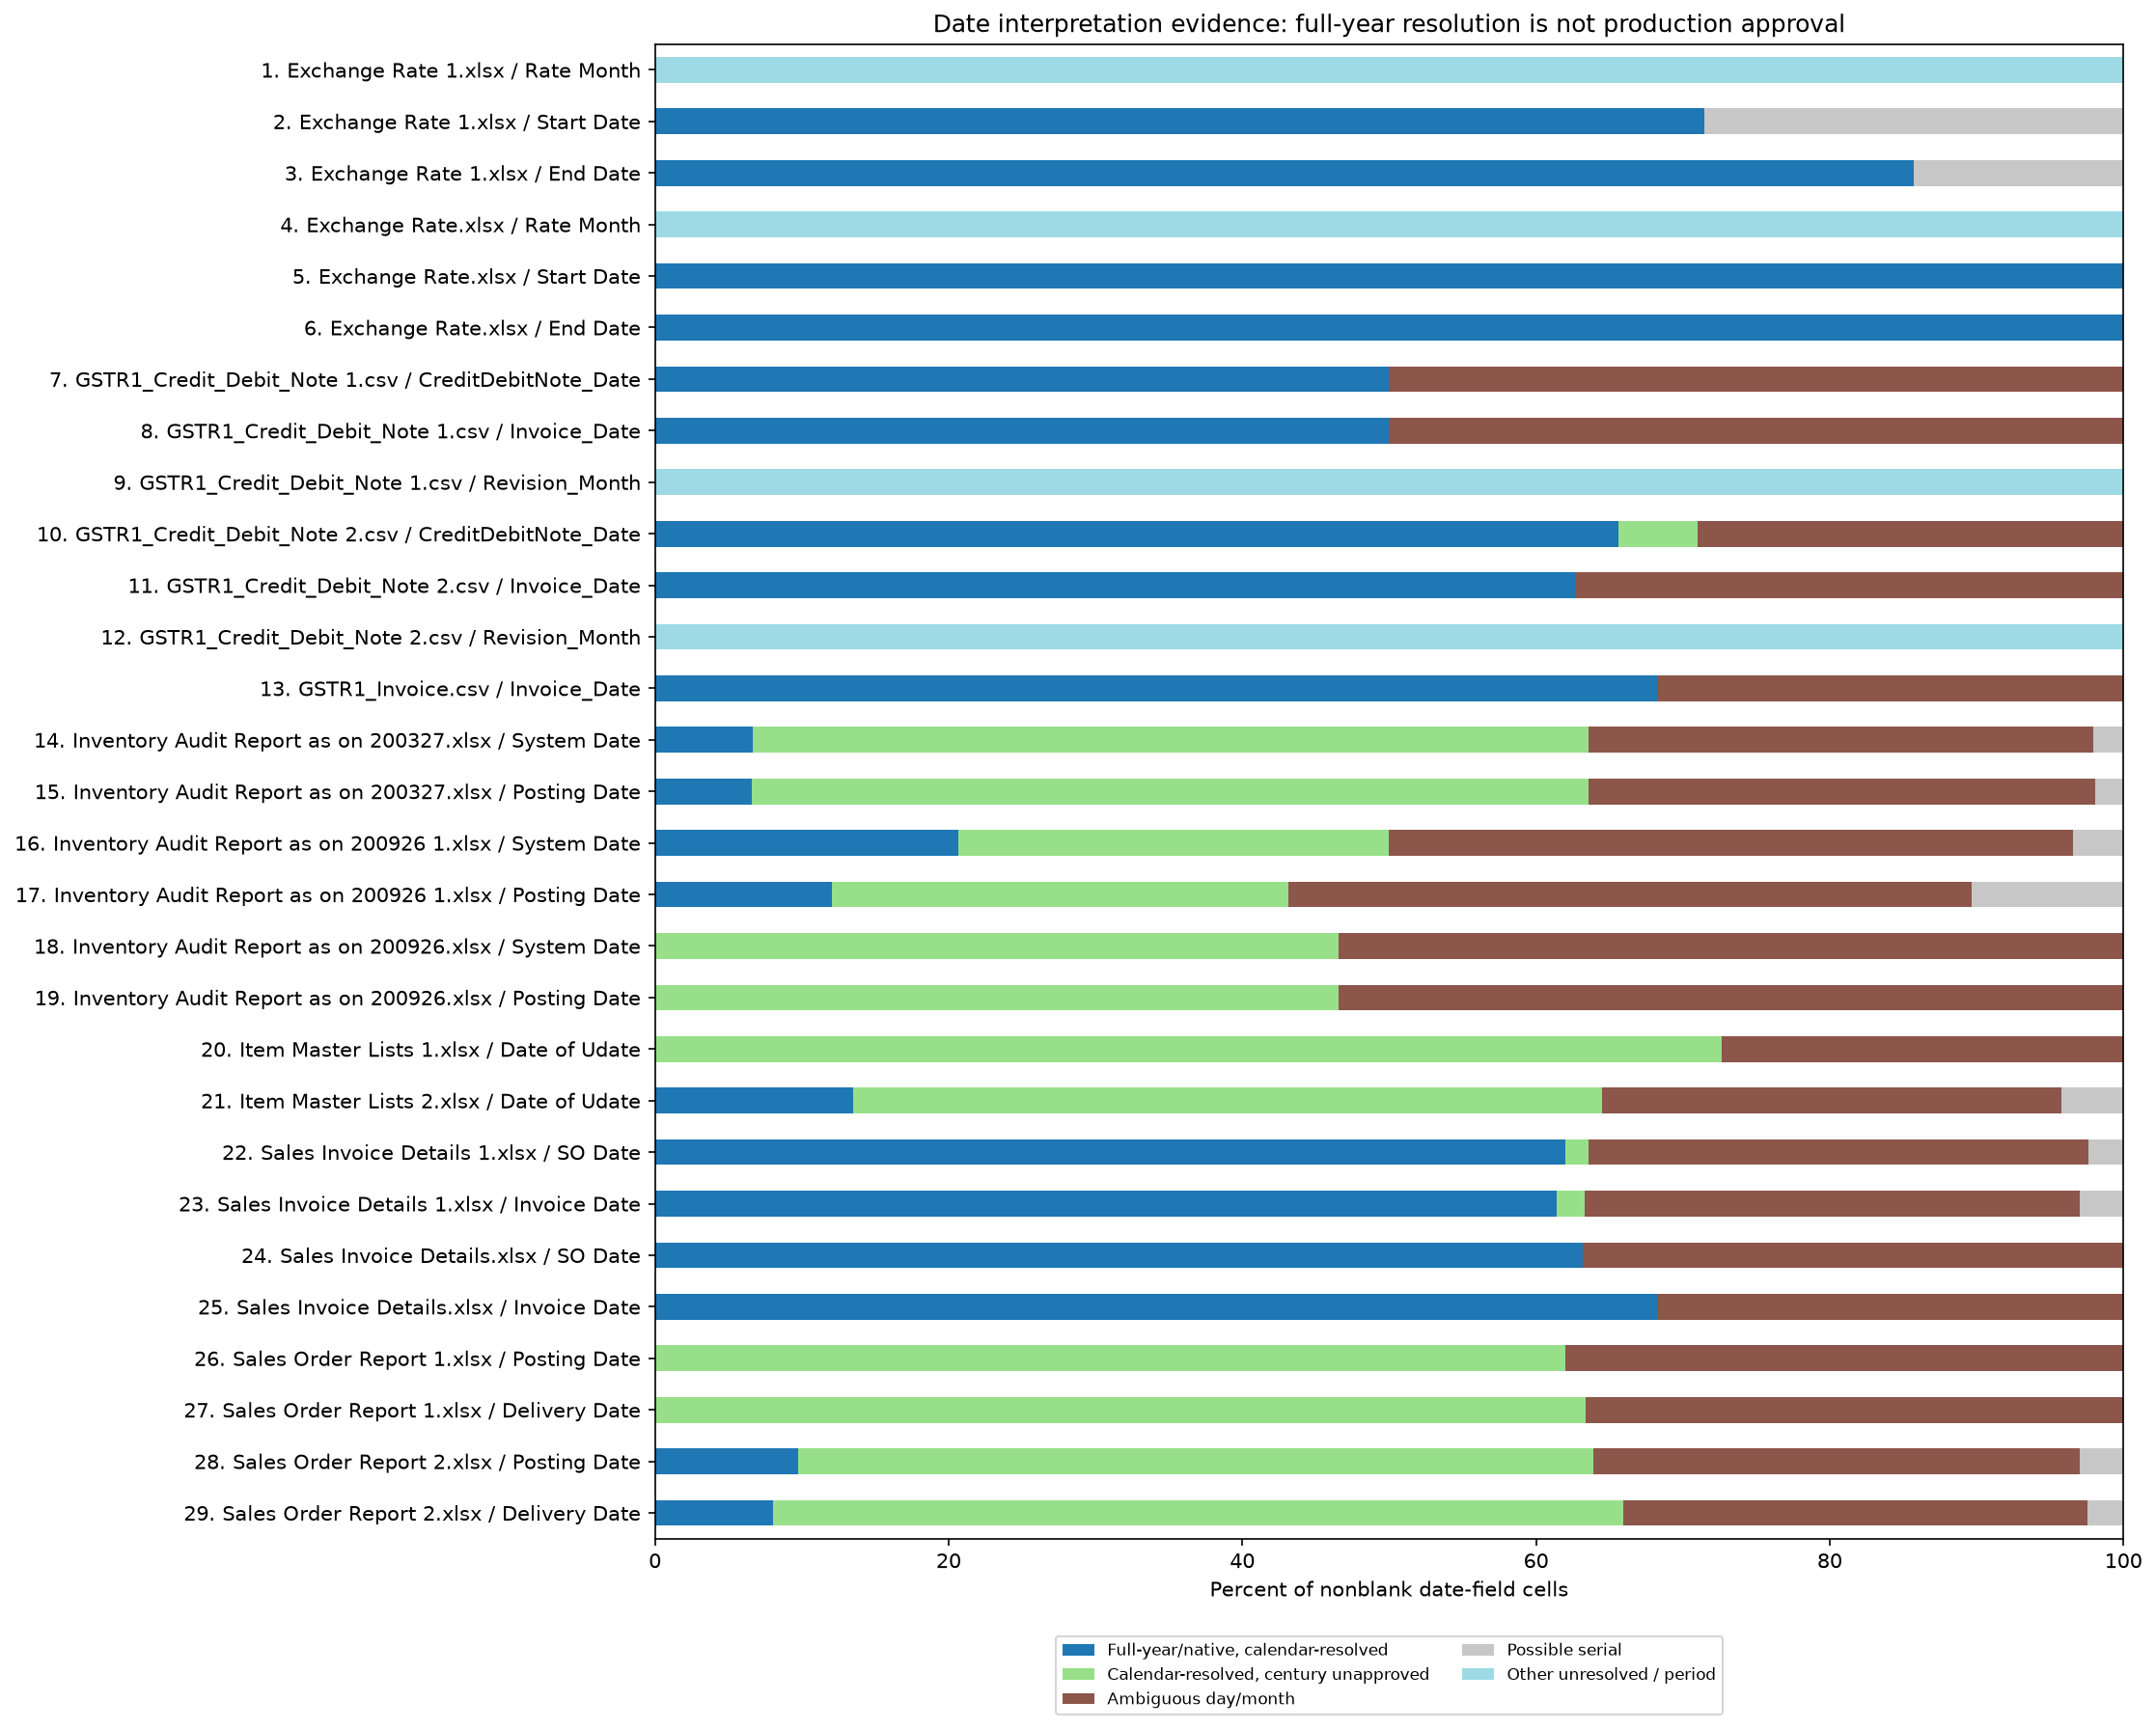

In [5]:
import matplotlib.pyplot as plt
view = coverage[coverage["nonblank_date_cells"] > 0].copy()
parts = pd.DataFrame({"Full-year/native, calendar-resolved": view["explicit_full_year_or_native_cells"], "Calendar-resolved, century unapproved": view["calendar_resolved_cells_under_prior_century_convention"] - view["explicit_full_year_or_native_cells"], "Ambiguous day/month": view["ambiguous_day_month_cells"], "Possible serial": view["possible_serial_cells"]}, index=view.index)
parts["Other unresolved / period"] = view["nonblank_date_cells"] - parts.sum(axis=1)
assert (parts >= 0).all().all()
percent = parts.div(view["nonblank_date_cells"], axis=0) * 100
percent.index = [(str(i+1) + ". " + str(row["file"]) + " / " + row["column"].strip()) for i, (_, row) in enumerate(view.iterrows())]
ax = percent.plot.barh(stacked=True, figsize=(15, 12), colormap="tab20")
ax.set(xlabel="Percent of nonblank date-field cells", title="Date interpretation evidence: full-year resolution is not production approval")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=8)
ax.figure.tight_layout()
image_path = assessment.evidence / "date_interpretation_coverage.png"
ax.figure.savefig(image_path, dpi=150, bbox_inches="tight")
plt.close(ax.figure)
display(Image(filename=str(image_path)))

## Requested use cases and explicit target proposals

Review sales, revenue, propensity, product/service demand and inventory first. Equations are proposals only; no target values are generated. Horizon and frequency are business requirements that have not been supplied. A proxy is never silently substituted for the requested outcome.

In [6]:
examples = results["assessment_examples"]
display(examples[examples["scope"] == "Primary requested example"][["assessment_id", "use_case", "feasibility", "proposed_target", "target_definition_proposal", "method_suitability", "evidence_and_history", "limitations_and_dependencies"]])
display(results["target_source_bindings"])

,assessment_id,use_case,feasibility,proposed_target,target_definition_proposal,method_suitability,evidence_and_history,limitations_and_dependencies
0,T01,Sales forecasting,Feasible with Conditions,Future count of distinct scoped invoice refere...,Proposed only: COUNT DISTINCT(Invoice Num at o...,Time-series count forecasting after source/tim...,Small invoice: 337 lines / 234 document refere...,"Source authenticity, invoice scope/date rules,..."
1,T02,Revenue forecasting,Feasible with Conditions,Future additive invoiced taxable value per app...,Proposed only: SUM(reported Taxable Value) on ...,Time-series value forecasting conditional on a...,337 small invoice lines correspond to GST repr...,"Actual revenue recognition, collections and pr..."
2,T03,Customer purchase propensity,Not Currently Feasible,"P(purchase in (t,t+H] | information available ...",Proposed definition only: positive if approved...,Supervised classification or event-time approa...,Customer/order references and purchases-like e...,Approved customer crosswalk; onboarding/eligib...
3,T04,Product/service demand forecasting,Feasible with Conditions,"Future product-period reported quantity, or se...",Proposed only: SUM(Quantity) for approved prod...,Per-series or pooled time-series strategy depe...,Small invoice has 323 G and 14 S lines; large ...,"Approved item/foreign-code crosswalks, returns..."
4,T05,Inventory forecasting,Not Currently Feasible,Future stock balance or probability of stockou...,Desired balance identity only: approved openin...,Inventory balance planning/rules may be suffic...,"Large audit has 98,104 movement rows without r...","Opening balances, stable movement/product/ware..."


,assessment_id,file,worksheet,actual_column_name,column_number,review_role,source_rows,source_nonempty_rows,source_columns,nonblank_values,missing_values,source_types,date_evidence_reference,identifier_distinct,identifier_null_rows,identifier_duplicate_excess,identifier_prior_semantic_role,business_mapping_approved,reference
0,T01,Sales Invoice Details.xlsx,Sheet1,Invoice Date,8,event / document / scope,337,337,43,337,0,"{""text"": 337}",historical_date_coverage: Sales Invoice Detail...,,,,Not among prior identifier candidates,False,../data_inventory/validation/column_validation...
1,T01,Sales Invoice Details.xlsx,Sheet1,Invoice Num,7,event / document / scope,337,337,43,337,0,"{""text"": 337}",Not a profiled date field,234,0,103,entity/document reference; candidate only,False,../data_inventory/validation/column_validation...
2,T01,Sales Invoice Details.xlsx,Sheet1,TransType,2,event / document / scope,337,337,43,337,0,"{""text"": 337}",Not a profiled date field,,,,Not among prior identifier candidates,False,../data_inventory/validation/column_validation...
3,T01,Sales Order Report 1.xlsx,Sheet1,Posting Date,9,"Alternative order activity, not interchangeabl...",1098,1098,26,1098,0,"{""text"": 1098}",historical_date_coverage: Sales Order Report 1...,,,,Not among prior identifier candidates,False,../data_inventory/validation/column_validation...
4,T01,Sales Order Report 1.xlsx,Sheet1,SO No,7,"Alternative order activity, not interchangeabl...",1098,1098,26,1098,0,"{""number"": 1098}",Not a profiled date field,299,0,799,entity/document reference; candidate only,False,../data_inventory/validation/column_validation...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,T13,Exchange Rate.xlsx,INR to JPY,Start Date,2,Explicit synthetic source,22,22,7,22,0,"{""datetime"": 22}",historical_date_coverage: Exchange Rate.xlsx /...,22,0,0,date/period attribute; not established as a pr...,False,../data_inventory/validation/column_validation...
114,T13,Exchange Rate.xlsx,INR to JPY,End Date,3,Explicit synthetic source,22,22,7,22,0,"{""datetime"": 22}",historical_date_coverage: Exchange Rate.xlsx /...,22,0,0,date/period attribute; not established as a pr...,False,../data_inventory/validation/column_validation...
115,T13,Exchange Rate.xlsx,INR to JPY,From Currency,4,Explicit synthetic source,22,22,7,22,0,"{""text"": 22}",Not a profiled date field,,,,Not among prior identifier candidates,False,../data_inventory/validation/column_validation...
116,T13,Exchange Rate.xlsx,INR to JPY,To Currency,5,Explicit synthetic source,22,22,7,22,0,"{""text"": 22}",Not a profiled date field,,,,Not among prior identifier candidates,False,../data_inventory/validation/column_validation...


## Reusable predictive capability families and unseen requests

The system must accept previously unseen requests when evidence supports their outcome/observation contract. These human-reviewed examples are not an application question catalogue. Historical retrieval/rules, forecasting, unknown-outcome regression, classification, event-time and other tasks have different requirements. No single algorithm is selected or implemented.

In [7]:
display(results["reusable_capability_assessment"])
display(examples[examples["scope"] != "Primary requested example"][["use_case", "feasibility", "evidence_and_history", "limitations_and_dependencies"]])

,capability_family,data_contract_requirement,method_family_not_fixed_algorithm,feasibility,limitation
0,Historical retrieval / aggregation,Observed facts within approved scope,SQL/dataframe grouping or documented arithmetic,Feasible with Conditions,No model needed; dates/units/authority/grain s...
1,Descriptive quality diagnostics,Existing source/metadata counts,Reproducible read-only profiling,Feasible,"Already verified source extents, missingness, ..."
2,Future aggregate count process,Mature scoped events over complete buckets,Time-series candidates and non-ML count baselines,Feasible with Conditions,Invoice activity is the least measure-dependen...
3,Future additive numerical process,Approved additive amount/quantity and coherent...,Time-series family chosen after diagnostics/va...,Feasible with Conditions,Entity/unit/currency and fiscal/sign semantics...
4,Unknown numerical outcome at decision time,Comparable historical input/outcome pairs and ...,Supervised regression when labels are defensible,Not Currently Feasible,Observed amount columns do not establish retro...
5,Future categorical/propensity outcome,"Eligible population, matured positive/negative...",Classification or event-time family,Not Currently Feasible,No defensible negative purchase cohort or hist...
6,Duration / time-to-event,"Actual timed events, origins and censoring",Event-time or numerical duration family,Not Currently Feasible,Actual completion/payment lifecycle unverified
7,Hierarchical / multi-series forecasts,Approved shared target plus per-entity history...,"Per-series/pooled/hierarchical options, assess...",Feasible with Conditions,Current crosswalks and memberships unapproved;...
8,Operational stock trajectories,Validated opening state and typed flows/as-of ...,Balance rules for known movements; predictive ...,Not Currently Feasible,"Grouped movement context, replenishment and st..."
9,Anomaly diagnostics,Approved rules or stable reference distribution,Rule-based or exploratory unsupervised diagnos...,Feasible with Conditions,"A flag is not a fraud label, causal finding, p..."


,use_case,feasibility,evidence_and_history,limitations_and_dependencies
5,Unknown numerical outcomes,Not Currently Feasible,"Numerical fields exist, but no approved quote/...","Decision records, effective/available timestam..."
6,Cancellation or adjustment risk,Not Currently Feasible,"Small order has current 44 Canceled lines, 50 ...","Status event log, decision-time state/features..."
7,Delivery time or delay prediction,Not Currently Feasible,Posting Date and Delivery Date exist; large de...,"Promise revisions, actual shipment/delivery/co..."
8,"Collections, cash flow, recognized revenue or ...",Not Currently Feasible,Schema lacks identified actual-payment/settlem...,"Receivables/payments, allocations, general led..."
9,Tax/adjustment activity forecasting,Feasible with Conditions,6-row notes have 6 scoped references; 276 none...,"Filing versions, dates, note scope/sign, compl..."
10,Hierarchical or segmented forecasting,Feasible with Conditions,Customer/item and PTC/PCT classification candi...,"Validated hierarchy, time-varying memberships,..."
11,"Historical retrieval, aggregations and diagnos...",Feasible with Conditions,20 validated tables / 521 columns and existing...,"Clarify metric, scope, time basis and join saf..."
12,Currency rate forecasting,Not Currently Feasible,Only 7 and 22 explicitly synthetic monthly rat...,"Production market/contract rates, fixing calen..."


## Propensity outcomes, join risks and temporal leakage

Nonpurchasing negatives require eligibility plus complete follow-up within an approved H; missing transactions, zero quantities and current inactive flags do not supply negative labels. Future/planned records are not mature realized history. Existing candidate relationships stay unapproved; source/financial fanout must be controlled before target enrichment.

In [8]:
display(results["propensity_outcome_audit"])
relationships = results["relationship_dependency_evidence"]
display(relationships[(relationships["controlled_join_tested"]) & (relationships["predicted_excess_left_rows"] > 0)][["relationship_id", "source_table", "source_column", "target_table", "target_column", "source_rows", "predicted_left_join_rows", "prediction_dependency_note"]])
display(results["leakage_and_validation_controls"])

,element,status,evidence,required_action
0,Positive purchase evidence,Candidate events only,Order and invoice references exist; order plac...,"Confirm purchase event and customer mapping, n..."
1,Historical negative outcomes,Not established,No verified eligible-and-fully-observed no-pur...,"Obtain eligibility, complete event capture and..."
2,Defensible prediction window,Not supplied,"No approved t/H, extraction closure or label-r...","NOP must define decision cadence, future windo..."
3,Customer risk set,Not historical,"Small master has 40 codes, and all 40 appear a...",Obtain historical entry/exit/activity and comp...
4,Entity identity,Unapproved,135 ID candidates remain unconfirmed; invoice ...,Approve scoped customer and event identity bef...
5,Features at decision,Availability history absent,No approved availability timestamps or prior-s...,Specify point-in-time admissible inputs; no fe...


,relationship_id,source_table,source_column,target_table,target_column,source_rows,predicted_left_join_rows,prediction_dependency_note
12,REL-013,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),"[""Invoice_Number""]",Sales Invoice Details.xlsx :: Sheet1,"[""Invoice Num""]",6,14,Direct enrichment can repeat target/financial ...
14,REL-015,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),"[""Invoice_Number""]",Sales Invoice Details 1.xlsx :: Sheet1,"[""Invoice Num""]",279,873,Direct enrichment can repeat target/financial ...
15,REL-016,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),"[""Invoice_Number""]",Sales Invoice Details.xlsx :: Sheet1,"[""Invoice Num""]",279,310,Direct enrichment can repeat target/financial ...
21,REL-022,Inventory Audit Report as on 200327.xlsx :: Sh...,"["" Item No. ""]",Item Master Lists 2.xlsx :: Item Lists,"[""Item No.""]",108129,108141,Direct enrichment can repeat target/financial ...
62,REL-063,Sales Invoice Details 1.xlsx :: Sheet1,"[""SO Num""]",Sales Order Report 1.xlsx :: Sheet1,"[""SO No""]",100188,101376,Direct enrichment can repeat target/financial ...
63,REL-064,Sales Invoice Details 1.xlsx :: Sheet1,"[""SO Num""]",Sales Order Report 2.xlsx :: Sheet1,"[""SO No""]",100188,402400,Direct enrichment can repeat target/financial ...
76,REL-077,Sales Invoice Details.xlsx :: Sheet1,"[""SO Num""]",Sales Order Report 1.xlsx :: Sheet1,"[""SO No""]",337,1347,Direct enrichment can repeat target/financial ...
77,REL-078,Sales Invoice Details.xlsx :: Sheet1,"[""SO Num""]",Sales Order Report 2.xlsx :: Sheet1,"[""SO No""]",337,730,Direct enrichment can repeat target/financial ...
109,REL-110,Sales Order Report 2.xlsx :: Sheet1,"["" Customer Code ""]",Customer Master Report 2.xlsx :: Sheet1,"[""CUSTOMER CODE""]",100286,100898,Direct enrichment can repeat target/financial ...
110,REL-111,Sales Order Report 2.xlsx :: Sheet1,"["" Customer Code ""]",Customer Master Report 2.xlsx :: Sheet1,"[""CUSTOMER CODE""]",100286,100932,Direct enrichment can repeat target/financial ...


,risk,affected_evidence,potential_leakage,required_chronological_control,status
0,Current state as historical feature,Status / ACTIVE / INACTIVE / current master stock,Post-outcome or future updates can encode labe...,Require historical state effective/available a...,Required; not implemented or validated through...
1,Future or planned events,"Future Invoice Date, Posting Date, Delivery Da...",Future/planned entries can be mistaken for rea...,Use source-supported actual/known-at-time role...,Required; not implemented or validated through...
2,Outcome arithmetic in predictors,"Price, quantity, taxable/base and tax totals",Target components can trivially reconstruct an...,Confirm which values are available at the deci...,Required; not implemented or validated through...
3,Cross-export and duplicate leakage,Overlapping invoice/GST and duplicate signatures,Same event can enter training and test or be c...,Approved lineage/event identity across splits;...,Required; not implemented or validated through...
4,Label-window overlap,"Customer/doc outcomes over (t,t+H]",Training labels may use events after validatio...,"At fold cutoff c, require training outcome win...",Required; not implemented or validated through...
5,Retrospective customer eligibility,Current master and missing transactions,Missing events are wrongly assigned negative l...,Eligibility and complete capture for entire wi...,Required; not implemented or validated through...
6,Future dimension joins,Master classifications and synthetic reference...,Latest attributes can reveal future entity state.,Approved many-to-one effective/available-time ...,Required; not implemented or validated through...
7,Global preprocessing / selection,"Transforms, imputation, features, hierarchy or...",Future distributions or holdout outcomes conta...,Fit on each training fold only; compare candid...,Required; not implemented or validated through...
8,Artificial continuity / zeros,Gaps and unobserved bucket/entity periods,Zero-filled missing capture creates fabricated...,Approve business calendar and coverage first; ...,Required; not implemented or validated through...
9,Current financial totals,"Document total repeated on lines, credit notes...",Post-decision settlements/adjustments or repea...,"Approved line/document measure, revision cutof...",Required; not implemented or validated through...


## Data requirements and unresolved findings

All 424 quality issues and the known date, duplicate, financial, synthetic-data, unnamed-field and identity uncertainties are preserved. Additional eligibility/availability/actual event, stock or finance lifecycle sources are required for several outcomes. Complete history at the requested target grain must be assessed before any training.

In [9]:
display(results["data_requirements"])
display(results["outcome_availability_audit"])
display(results["unresolved_issue_summary"])
assert len(results["unresolved_issue_dependencies"]) == 424

,requirement_id,requirement,applies_to,owner_to_confirm,required_resolution,status,observed_evidence
0,REQ-001,Business metric contract,All predictive requests,NOP process owner,"Decide the intended outcome, unit, scope, even...",Open,Column names alone do not establish the outcome.
1,REQ-002,Decision horizon and cadence,All predictive requests,NOP process owner,"Specify H, lookback, decision frequency and us...",Open,Choose validation only after H and decision cl...
2,REQ-003,Source production authority,All source-dependent tasks,Source system owners,"Verify real versus synthetic/sample data, extr...",Open,Two rate sheets and reference customer list ex...
3,REQ-004,Date and century rules,All temporal tasks,Source owners,"Approve source/field-specific DMY/MDY, century...",Open,203455 ambiguous / 28 impossible / 14949 seria...
4,REQ-005,Observation cutoff and availability,All predictive tasks,Data operations,"Supply extraction completion, ingestion/availa...",Open,Future-dated records cannot be assumed realize...
5,REQ-006,Complete periods and missingness,All time series,Data operations / business owner,"Distinguish no activity, out-of-scope, unobser...",Open,Unobserved dates/months in partial coverage ar...
6,REQ-007,Stable invoice/document scope,Count/value forecasting,ERP owner,Confirm issuer/year/series and persistent line...,Open,Small invoice has 234 internally consistent re...
7,REQ-008,Sales-order scope,Order-driven tasks,ERP owner,Explain reused SO numbers and validate composi...,Open,275 of 299 raw small SO groups span multiple c...
8,REQ-009,Duplicate/extract precedence,All quantitative targets,Data owner,"Confirm repeated line legitimacy, 3 exact dupl...",Open,No deduplication authorized; source payload ag...
9,REQ-010,Additive monetary measure,Value forecasting,Finance owner,"Approve taxable/gross/net basis, currency, fre...",Open,Repeated Invoice Total Include GST is not addi...


,missing_requirement,needed_evidence,observed_schema_finding,affected_capability,absence_claim_scope
0,Eligibility/cohort history,"Customer onboarding, eligibility start/end, hi...",Current customer master status is a snapshot; ...,Propensity/churn,Not identified or validated in all 521 invento...
1,Event availability history,Ingestion/available timestamp and extraction c...,Event dates exist; transaction timestamps do n...,All prospective validation,Not identified or validated in all 521 invento...
2,Actual fulfilment outcomes,Actual delivery/service completion and censoring,Delivery Date is unconfirmed planned/actual; n...,Duration/delay,Not identified or validated in all 521 invento...
3,Financial lifecycle,"Actual settlement, recognition and realized COGS",Payment Terms and inventory Cost are not those...,Collections/recognized revenue/profit,Not identified or validated in all 521 invento...
4,Stock availability history,"Regular product/warehouse snapshots, typed mov...",Grouped inventory and current item stock canno...,Inventory/unconstrained demand,Not identified or validated in all 521 invento...
5,Decision/realization pairs,Historical decisions or quotes with realized o...,Invoice amounts are observed outcomes with no ...,Supervised numerical prediction,Not identified or validated in all 521 invento...
6,State transitions,Timestamped status/credit/cancellation lifecycle,Current Status and observed notes do not estab...,Cancellation/adjustment classification,Not identified or validated in all 521 invento...
7,Real production FX,Authorized observed currency fixing history,Only explicitly marked synthetic rate tables s...,Production FX forecasts,Not identified or validated in all 521 invento...


,issue,prior_affected_count,relationship_impact,status,evidence,feasibility_status
0,Ambiguous dates,203455,Date equality/order and temporal scope cannot ...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...
1,Impossible dates,28,Temporal joins and document chronology may fai...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...
2,Possible Excel serial dates,14949,Numeric values are unconfirmed date encodings;...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...
3,Excess exact duplicate rows,3,Can multiply relationship counts and financial...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...
4,Payload-duplicate candidates,972,Can expand keys; inventory repeated layout row...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...
5,Financial exceptions,,"Unresolved unit, discount, freight and GST rul...",Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...
6,Synthetic indicators,,High identifier overlap in sample material doe...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...
7,Unnamed PCT_NOPJ field,33,33 populated NOPJ values; likely agency/source...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...
8,Unconfirmed business identifiers,135,Empirical uniqueness and coverage are not appr...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...,Still unresolved; feasibility does not approve...


## Technology-independent architecture requirements

Future stages: interpret intent; discover authorized evidence; ground semantics; draft a versioned target/observation contract; check readiness or abstain/clarify; distinguish analytics from prediction; evaluate admissible strategies using chronological validation; version inference and monitor. This is documentation only. No engine, API, preparation pipeline or model is implemented.

In [10]:
display(results["architecture_requirements"])
display(results["target_contract_requirements"])

,component,required_capability,contract_or_output,guardrail,implementation_status
0,Request interpretation,"Extract outcome intent, entities, metric/unit,...",Versioned intent draft; preserve original requ...,No anticipated-question list; resolve only mat...,Assessment design only; not implemented
1,Authorized evidence discovery,"Discover current schemas, types, grains, time/...",Versioned evidence catalogue with actual sourc...,Column-name resemblance is insufficient; new d...,Assessment design only; not implemented
2,Semantic grounding / clarification,Bind requested meaning to supported fields and...,"Proposed semantic bindings, evidence and minim...",No invented columns/outcomes or silent metric ...,Assessment design only; not implemented
3,Target and observation contract,"Specify outcome equation, entity/record grain,...",Human-reviewable versioned target contract ind...,Business-rule configurations are reusable sema...,Assessment design only; not implemented
4,Evidence readiness / abstention gate,"Check source authenticity, complete periods, t...",Admissible / conditional / unsupported decisio...,Unsupported or ambiguous requests yield limita...,Assessment design only; not implemented
5,Task and strategy planning,"Separate retrieval/SQL/rules, numerical foreca...",Admissible strategy families and resource/busi...,No single algorithm and no fixed question/mode...,Assessment design only; not implemented
6,Reusable preparation interface — future only,"Honor the target contract with versioned, reus...",Lineage-preserving execution plan and fitted-t...,Not implemented or executed in this assessment...,Assessment design only; not implemented
7,Evaluation and candidate comparison — future only,"Select time-respecting folds, baselines, appro...",Auditable evaluation protocol and measured evi...,No made-up performance; fit transforms only wi...,Assessment design only; not implemented
8,Inference and explanation — future only,Apply approved fitted artifacts to an authoriz...,"Prediction versus observed fact, units, as-of ...",Block extrapolation beyond evaluated scope and...,Assessment design only; not implemented
9,"Monitoring, versioning and extension","Track freshness, schema/identity/semantic drif...",Registries of evidence/semantic contracts/comp...,New domains extend metadata/adapters/contracts...,Assessment design only; not implemented


,contract_field,required_definition,status
0,Outcome intent,Observed retrieval versus future/unknown outco...,Required design field; no production target co...
1,Business measure,"Approved equation, source fields, dimensional ...",Required design field; no production target co...
2,Entity and record grain,"Observation entity, scoped IDs and stable even...",Required design field; no production target co...
3,Population,"Eligibility, exposure, entry/exit and censoring",Required design field; no production target co...
4,Event clock,"Business date/time role, timezone/calendar and...",Required design field; no production target co...
5,Availability clock,When each input/outcome was actually knowable;...,Required design field; no production target co...
6,Decision cutoff,Explicit t and data snapshot/version available...,Required design field; no production target co...
7,Prediction horizon,Business-supplied H and usable decision lead time,Required design field; no production target co...
8,Observation / label window,"Outcome interval, reporting delay and maturity",Required design field; no production target co...
9,Lookback and granularity,"Allowed past interval, bucket, frequency and h...",Required design field; no production target co...


## Recommendation and validation

First conditional technical candidate: aggregate scoped invoice-document activity, after authenticity, source/time scope, completeness, H and adequate mature history are confirmed. Invoice count does not replace units, realized sales or recognized revenue. Conditional value/product capabilities follow their own measure contracts. Propensity and inventory need additional evidence. Stop for NOP requirements review and explicit approval before preparation or model development.

In [11]:
assert validation["all_inputs_unchanged"]
assert all(check["passed"] for check in validation["checks"])
assert all(check["complete_cell_content_verified"] for check in validation["export_checks"])
assert validation["models_trained"] == 0 and validation["prediction_targets_generated"] == 0
assert not validation["prediction_engine_implemented"]
display(pd.DataFrame(validation["export_checks"]))
display(Markdown((assessment.out / "business_prediction_feasibility_report.md").read_text(encoding="utf-8")))
print("Assessment complete. Preparation, feature engineering and model development have not begun.")

,workbook,sheet,evidence_csv,rows,columns,complete_cell_content_verified
0,prediction_target_mapping.xlsx,assessment_examples,feasibility_evidence/assessment_examples.csv,13,23,True
1,prediction_target_mapping.xlsx,target_source_bindings,feasibility_evidence/target_source_bindings.csv,118,19,True
2,prediction_target_mapping.xlsx,historical_date_coverage,feasibility_evidence/historical_date_coverage.csv,37,31,True
3,prediction_target_mapping.xlsx,reusable_capability_assessment,feasibility_evidence/reusable_capability_asses...,10,5,True
4,prediction_target_mapping.xlsx,source_grain_evidence,feasibility_evidence/source_grain_evidence.csv,20,11,True
5,prediction_target_mapping.xlsx,independent_grain_probes,feasibility_evidence/independent_grain_probes.csv,8,8,True
6,prediction_target_mapping.xlsx,measure_evidence,feasibility_evidence/measure_evidence.csv,114,26,True
7,prediction_target_mapping.xlsx,identifier_evidence,feasibility_evidence/identifier_evidence.csv,135,26,True
8,prediction_target_mapping.xlsx,relationship_dependency_evidenc,feasibility_evidence/relationship_dependency_e...,148,38,True
9,prediction_target_mapping.xlsx,financial_rule_evidence,feasibility_evidence/financial_rule_evidence.csv,35,15,True


# Business prediction requirements and target feasibility

Assessment date and diagnostic cutoff: **2026-11-02** (Asia/Calcutta date; no source event timezone is assumed). Scope: 17 original files, 20 tables, 521 columns, 37 date-related fields and 135 identifier candidates. This is an assessment, not a prediction platform implementation. No source joins, cleaning, duplicate removal, label/target values, features, training, forecasts or forecasting metrics were produced.

## Executive decision

There is **no unconditionally production-ready prediction target**. Sales activity, an approved invoiced-value proxy, selected product demand proxies, reporting activity and hierarchical extensions are **Feasible with Conditions**. Customer propensity, stock/stockout forecasts, actual delivery outcomes, decision-time numerical regression, cancellation risk, settlement/recognized revenue/margin and production FX forecasts are **Not Currently Feasible** under the supplied evidence. A descriptive evidence audit is already feasible and is not ML prediction.

**First prediction capability to develop, after business/data gates:** a reusable aggregate event-count forecasting capability, initially evaluated against scoped invoice-document activity in an authoritative single invoice source. The small invoice export has 337 detail rows / 234 full invoice references, with constant observed billing party/date/document total within each reference and matching GST representation. This candidate avoids monetary-unit arithmetic and order/invoice joins, but the 10-month partial date span, 107 ambiguous dates, extraction closure, scope and production provenance must be resolved. It cannot establish annual seasonality, performance, an approved horizon or complete observation periods. More mature history is needed if honest horizon/fold evaluation cannot be supported. Invoice activity must not be silently substituted for booked orders, shipped units or recognized revenue.

The longer small-order date span does **not** justify choosing order-count forecasting first: 275 of 299 raw SO-number groups span multiple customer codes, 278 vary Posting Date and its dates use an unapproved two-digit-year convention. These are scope/representation conflicts, not a confirmed count of erroneous business documents. No winner is selected by newest/largest filename.

## Classification meaning and task boundary

- **Feasible:** the exact bounded task has directly verified evidence and no unresolved prerequisite for that stated scope; here this applies to existing structural/descriptive diagnostics, not production prediction.
- **Feasible with Conditions:** observable ingredients support a precise candidate after listed gates; this is not model readiness, sufficient history certification or permission to resolve data issues.
- **Not Currently Feasible:** a defensible outcome, population, temporal availability, required state/history or production evidence is missing/unverified. A more complex algorithm cannot supply missing labels or semantics.

The five requested use cases below are assessment examples. Additional examples and capability families explore the evidence boundary; they are not a fixed supported-question catalogue, question-to-model table or manually programmed application responses. The future system must judge previously unseen requests against evidence and an approved target contract.

## Requested business use cases and broader examples

| assessment_id | use_case | feasibility | proposed_target | evidence_and_history | priority_recommendation |
| --- | --- | --- | --- | --- | --- |
| T01 | Sales forecasting | Feasible with Conditions | Future count of distinct scoped invoice references per approved complete time bucket | Small invoice: 337 lines / 234 document references, internally constant billing party/date/total; partial full-year dates span ten months. No annual-seasonality evidence and no approved extraction boundary. | Priority 1 candidate after gates: least dependence on monetary/unit rules and joins; never substitute invoice activity for another meaning of sales. |
| T02 | Revenue forecasting | Feasible with Conditions | Future additive invoiced taxable value per approved period, currency and entity scope | 337 small invoice lines correspond to GST representation, not additional revenue. Only ten months of partial dated coverage; quantity/base and tax arithmetic exceptions remain. | Conditional follow-on after count capability and finance-owned measure contract. |
| T03 | Customer purchase propensity | Not Currently Feasible | P(purchase in (t,t+H] \| information available at t) for an eligible customer | Customer/order references and purchases-like events exist, but all 40 small-order customer codes occur in the 40-row master. No verified historical nonpurchaser/cohort/exposure panel or eligibility start/end/observation boundary. Invoice customer mapping is unapproved. | Defer model development; obtain cohort and observation history before creating either class. |
| T04 | Product/service demand forecasting | Feasible with Conditions | Future product-period reported quantity, or service-period activity/value under a separately approved unit | Small invoice has 323 G and 14 S lines; large has 99,242 G and 941 S. Small order has 36 blank product rows; repeated SO scope and service-like zero quantities prevent a universal quantity target. UOM Manual is not a confirmed physical unit. | Conditional for sufficiently supported goods series; service duration/capacity and unconstrained demand are not currently supported. |
| T05 | Inventory forecasting | Not Currently Feasible | Future stock balance or probability of stockout over an approved horizon | Large audit has 98,104 movement rows without raw item code; three grouped audits are not a confirmed regular snapshot panel. Item master stock/update date is not repeated historical stock observation. | Defer stock and stockout models; approve movement reconstruction and obtain authoritative snapshots/movement lifecycle first. |
| T06 | Unknown numerical outcomes | Not Currently Feasible | Owner-selected realized numerical outcome at an explicit event/decision horizon | Numerical fields exist, but no approved quote/decision snapshot, actual realization linkage or availability timestamps establish a leakage-free supervised dataset. | Obtain the decision process and realized outcome history before selecting predictors or algorithms. |
| T07 | Cancellation or adjustment risk | Not Currently Feasible | Future event indicator within a defensible observation window | Small order has current 44 Canceled lines, 50 Open and 1,004 Closed; these are line states, not 44 uniquely scoped historical cancellation outcomes. No transition history or verified negatives. | Defer; existing states support descriptive audit only under known scope. |
| T08 | Delivery time or delay prediction | Not Currently Feasible | Actual completion duration, or actual-versus-promised lateness | Posting Date and Delivery Date exist; large delivery field contains 15 impossible dates and values extending to 2028-04-30 under partial interpretations. | Request actual fulfilment/service milestones; do not relabel planned dates as outcomes. |
| T09 | Collections, cash flow, recognized revenue or margin | Not Currently Feasible | Future settled cash, ledger-recognized amount or realized margin under an approved finance definition | Schema lacks identified actual-payment/settlement and recognition lifecycle fields. Inventory Cost/Trans. Value are not validated invoice-line COGS. | Additional financial lifecycle sources required, not a different algorithm. |
| T10 | Tax/adjustment activity forecasting | Feasible with Conditions | Future scoped note/event count or approved additive reported tax component per period | 6-row notes have 6 scoped references; 276 nonempty larger-note rows have 243 scoped references, 33 repeats and 3 exact excess duplicates. Much larger-note coverage extends beyond assessment date. | Lower priority; likely needs more mature production reporting history before forecasting. |
| T11 | Hierarchical or segmented forecasting | Feasible with Conditions | Same approved additive/count outcome per validated hierarchy level | Customer/item and PTC/PCT classification candidates exist; 27 row-preserving raw-key directions remain conditional. Larger master duplicates and partial matching can expand or lose records. | After aggregate target approval and entity-specific support assessment; not every segment can be forecast. |
| T12 | Historical retrieval, aggregations and diagnostics | Feasible with Conditions | No prediction target; approved recorded counts/sums/rates or audit findings | 20 validated tables / 521 columns and existing quality/relationship calculations support descriptive evidence. Business measures remain conditional on authority, grain and date rules. | Use now for evidence review; do not present a historical calculation as a forecast. |
| T13 | Currency rate forecasting | Not Currently Feasible | Future observed market/contract FX rate under an approved basis | Only 7 and 22 explicitly synthetic monthly rate records, overlapping two pairs/periods; some future periods and serial-date candidates. | Obtain authorized real rate history if this capability is required. |

Complete business objectives, proposed equations, source columns, date/key needs, scope, observation frequency, horizon requirements, limitations and method suitability are in [prediction_target_mapping.xlsx](prediction_target_mapping.xlsx), its `assessment_examples`, `target_source_bindings` and `historical_date_coverage` sheets. Formulas are proposed definitions, not generated target columns. All 13 examples have verified actual-column citations. Horizons have not been supplied by NOP; H, lead time, bucket and update cadence remain requirements rather than defaults.

### What can be generalized

| capability_family | data_contract_requirement | method_family_not_fixed_algorithm | feasibility | limitation |
| --- | --- | --- | --- | --- |
| Historical retrieval / aggregation | Observed facts within approved scope | SQL/dataframe grouping or documented arithmetic | Feasible with Conditions | No model needed; dates/units/authority/grain still govern business aggregates |
| Descriptive quality diagnostics | Existing source/metadata counts | Reproducible read-only profiling | Feasible | Already verified source extents, missingness, raw duplicates and relationship fanout; this is analytics, not prediction |
| Future aggregate count process | Mature scoped events over complete buckets | Time-series candidates and non-ML count baselines | Feasible with Conditions | Invoice activity is the least measure-dependent first candidate; no annual evidence from ten months |
| Future additive numerical process | Approved additive amount/quantity and coherent time series | Time-series family chosen after diagnostics/validation | Feasible with Conditions | Entity/unit/currency and fiscal/sign semantics; no universal algorithm |
| Unknown numerical outcome at decision time | Comparable historical input/outcome pairs and as-of availability | Supervised regression when labels are defensible | Not Currently Feasible | Observed amount columns do not establish retrospective decision examples |
| Future categorical/propensity outcome | Eligible population, matured positive/negative windows | Classification or event-time family | Not Currently Feasible | No defensible negative purchase cohort or historical availability panel |
| Duration / time-to-event | Actual timed events, origins and censoring | Event-time or numerical duration family | Not Currently Feasible | Actual completion/payment lifecycle unverified |
| Hierarchical / multi-series forecasts | Approved shared target plus per-entity history and hierarchy | Per-series/pooled/hierarchical options, assessed empirically | Feasible with Conditions | Current crosswalks and memberships unapproved; global row counts do not establish series support |
| Operational stock trajectories | Validated opening state and typed flows/as-of snapshots | Balance rules for known movements; predictive inputs only where uncertain | Not Currently Feasible | Grouped movement context, replenishment and stockout outcomes missing/unconfirmed |
| Anomaly diagnostics | Approved rules or stable reference distribution | Rule-based or exploratory unsupervised diagnostics | Feasible with Conditions | A flag is not a fraud label, causal finding, probability or forecast confidence |

Schema/quality/lineage discovery, grain/identity evidence, point-in-time contracts, readiness checks, validation protocols and component interfaces can generalize. Business meanings, eligibility, time roles, units, signs, source authority, event identities and outcome windows require target-specific approved semantic configurations. Those configurations describe data and business meaning, not anticipated questions or a model chosen by keyword.

## Actual source evidence and historical suitability

All 20 tables retain the meanings and uncertainties in [granularity evidence](dataset_granularity_report.xlsx). Customer/item masters are current reference candidates, not historical eligibility or attribute panels. Sales orders and invoices contain detail rows, tax exports are reporting representations, inventory is a grouped mixed-grain report, and rate examples are explicitly synthetic. Country/product classifications are references, not predictive outcome histories. Source rows are not independent time observations, invoice totals are repeated at line grain and similar schemas do not establish identical grain.

### Dates and observation counts

The following coverage is **timestamp evidence only**, not a cleaned time series or a count of supervised examples. Calendar-resolved ranges from prior validation can depend on a two-digit-year convention. A separate conservative view includes only native/full-year, one-interpretation dates at or before 2026-11-02, excluding century-dependent tokens from that view without changing or discarding any source records. ISO strings already present in date evidence are read; raw source dates are not reinterpreted. Neither view proves actual-versus-planned meaning, completeness, decision-time availability or production legitimacy.

| file | worksheet | column | calendar_resolved_min_under_prior_convention | calendar_resolved_max_under_prior_convention | century_dependent_cells_including_ambiguous | strict_partial_history_min | strict_partial_history_max | distinct_observed_months_asof | calendar_resolved_beyond_asof | explicit_full_year_or_native_beyond_asof |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Exchange Rate 1.xlsx | INR to JPY | Rate Month   |  |  | 2 |  |  | 0 | 0 | 0 |
| Exchange Rate 1.xlsx | INR to JPY | Start Date | 2026-08-21 | 2027-01-21 | 0 | 2026-08-21 | 2026-09-21 | 2 | 3 | 3 |
| Exchange Rate 1.xlsx | INR to JPY | End Date | 2026-09-20 | 2027-03-20 | 0 | 2026-09-20 | 2026-10-20 | 2 | 4 | 4 |
| Exchange Rate.xlsx | INR to JPY | Rate Month |  |  | 22 |  |  | 0 | 0 | 0 |
| Exchange Rate.xlsx | INR to JPY | Start Date | 2024-12-21 | 2026-09-21 | 0 | 2024-12-21 | 2026-09-21 | 22 | 0 | 0 |
| Exchange Rate.xlsx | INR to JPY | End Date | 2025-01-20 | 2026-10-20 | 0 | 2025-01-20 | 2026-10-20 | 22 | 0 | 0 |
| GSTR1_Credit_Debit_Note 1.csv | (CSV table) | CreditDebitNote_Date | 2026-01-29 | 2026-06-24 | 0 | 2026-01-29 | 2026-06-24 | 3 | 0 | 0 |
| GSTR1_Credit_Debit_Note 1.csv | (CSV table) | Invoice_Date | 2026-01-18 | 2026-03-30 | 0 | 2026-01-18 | 2026-03-30 | 2 | 0 | 0 |
| GSTR1_Credit_Debit_Note 1.csv | (CSV table) | Original_CreditDebitNote_Date |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Credit_Debit_Note 1.csv | (CSV table) | Revision_Month |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Credit_Debit_Note 1.csv | (CSV table) | Shipping_Bill_Date |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Credit_Debit_Note 2.csv | (CSV table) | CreditDebitNote_Date | 2026-04-25 | 2027-03-20 | 16 | 2026-09-21 | 2026-10-31 | 2 | 140 | 129 |
| GSTR1_Credit_Debit_Note 2.csv | (CSV table) | Invoice_Date | 2026-03-30 | 2027-03-17 | 0 | 2026-03-30 | 2026-10-31 | 8 | 106 | 106 |
| GSTR1_Credit_Debit_Note 2.csv | (CSV table) | Original_CreditDebitNote_Date |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Credit_Debit_Note 2.csv | (CSV table) | Revision_Month |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Credit_Debit_Note 2.csv | (CSV table) | Shipping_Bill_Date |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Invoice.csv | (CSV table) | Invoice_Date | 2025-12-21 | 2026-09-13 | 0 | 2025-12-21 | 2026-09-13 | 10 | 0 | 0 |
| GSTR1_Invoice.csv | (CSV table) | Original_Invoice_Date |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Invoice.csv | (CSV table) | AdvanceReceipt_Date |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Invoice.csv | (CSV table) | Shipping_Bill_Date |  |  | 0 |  |  | 0 | 0 | 0 |
| GSTR1_Invoice.csv | (CSV table) | Revision_Month |  |  | 0 |  |  | 0 | 0 | 0 |
| Inventory Audit Report as on 200327.xlsx | Sheet1 | System Date | 2026-09-21 | 2027-03-20 | 88116 | 2026-09-21 | 2026-11-02 | 3 | 46016 | 4895 |
| Inventory Audit Report as on 200327.xlsx | Sheet1 | Posting Date | 2026-09-21 | 2027-03-20 | 88219 | 2026-09-21 | 2026-11-02 | 3 | 45999 | 4796 |
| Inventory Audit Report as on 200926 1.xlsx | Sheet1 | System Date | 2026-08-22 | 2026-09-19 | 39 | 2026-08-22 | 2026-09-13 | 2 | 0 | 0 |
| Inventory Audit Report as on 200926 1.xlsx | Sheet1 | Posting Date | 2026-08-22 | 2026-09-15 | 41 | 2026-08-22 | 2026-09-13 | 2 | 0 | 0 |
| Inventory Audit Report as on 200926.xlsx | Sheet1 | System Date | 2026-08-22 | 2026-09-19 | 58 |  |  | 0 | 0 | 0 |
| Inventory Audit Report as on 200926.xlsx | Sheet1 | Posting Date | 2026-08-22 | 2026-09-19 | 58 |  |  | 0 | 0 | 0 |
| Item Master Lists 1.xlsx | Item Lists | Date of Udate | 2024-10-20 | 2026-09-17 | 150 |  |  | 0 | 0 | 0 |
| Item Master Lists 2.xlsx | Item Lists | Date of Udate | 2024-10-20 | 2026-09-17 | 3978 | 2024-11-25 | 2026-09-17 | 23 | 0 | 0 |
| Sales Invoice Details 1.xlsx | Sheet1 | SO Date | 2025-12-16 | 2027-03-19 | 2507 | 2025-12-16 | 2026-11-02 | 5 | 45931 | 44774 |
| Sales Invoice Details 1.xlsx | Sheet1 |  Invoice Date  | 2026-01-01 | 2027-03-20 | 2979 | 2026-01-01 | 2026-11-02 | 4 | 50771 | 49267 |
| Sales Invoice Details.xlsx | Sheet1 | SO Date | 2025-11-26 | 2026-08-25 | 0 | 2025-11-26 | 2026-08-25 | 10 | 0 | 0 |
| Sales Invoice Details.xlsx | Sheet1 | Invoice Date | 2025-12-21 | 2026-09-13 | 0 | 2025-12-21 | 2026-09-13 | 10 | 0 | 0 |
| Sales Order Report 1.xlsx | Sheet1 | Posting Date | 2024-04-13 | 2026-09-19 | 1098 |  |  | 0 | 0 | 0 |
| Sales Order Report 1.xlsx | Sheet1 | Delivery Date | 2024-04-16 | 2026-10-19 | 1098 |  |  | 0 | 0 | 0 |
| Sales Order Report 2.xlsx | Sheet1 | Posting Date   | 2026-08-13 | 2027-03-20 | 85323 | 2026-08-15 | 2026-11-02 | 4 | 47413 | 7381 |
| Sales Order Report 2.xlsx | Sheet1 | Delivery Date | 2026-08-22 | 2028-04-30 | 88063 | 2026-08-22 | 2026-11-02 | 4 | 54764 | 6693 |

- Small invoice and GST invoice `Invoice Date` / `Invoice_Date`: 337 cells each; 107 ambiguous, 230 full-year calendar-resolved, with partial 2025-12-21 to 2026-09-13 coverage over 10 observed months. These are corresponding source representations, not 674 new line observations or 20 months of history.
- Small order `Posting Date`: 1,098 cells; 417 ambiguous. Prior calendar resolution gives a partial 2024-04-13 to 2026-09-19 range, but every date depends on the century convention. Zero rows in the conservative full-year view does not mean no source dates exist. Raw SO grouping is also unstable.
- Large invoice ` Invoice Date `: 100,183 nonblank cells, 33,782 ambiguous and 2,996 possible serial candidates; its partial calendar range reaches 2027-03-20. Large order posting/delivery fields also extend beyond the assessment cutoff; a future delivery date may be a plan, not an observed outcome.
- Period labels such as rate `2027-03` remain monthly periods. Item `Date of Udate` is an update attribute, not a purchase/stock observation date. Revision month without a year cannot establish event history.
- Daily, ISO-weekly and monthly distinct timestamp support is recorded per field in the workbook, with both partial spans and unobserved months. This does not authorize daily/weekly/monthly target aggregation. Approved calendars and capture completeness are required before interpreting an empty bucket as zero. No zero filling or aggregation of business targets occurred.
- Sufficiency depends on complete mature observations at the requested entity/frequency relative to H, validation folds, seasonality and decision utility. There is no universal minimum-row threshold. Ten partial months do not establish annual seasonality; hundreds of thousands of lines over a short or future-dated interval do not establish long production history.

## Identifiers, grain and join dependencies

Existing evidence: [relationship report](dataset_relationship_report.md), [identifier and relationship matrix](identifier_relationship_matrix.xlsx), [logical business model](data_model_diagram/README.md). All 148 candidate comparisons and 69 controlled joins retain their original conditional status; no business keys/relationships are approved by this assessment.

- Invoice/order SO-only join: **100,188 -> 402,400 rows**, quantity **363,277 -> 1,472,651**. This is row replication, not growth or extra demand. Do not enrich targets through that direct detail join.
- Small GST/invoice scoped document join: **337 -> 609 rows**. Scoped invoice + raw item description aligns **337 -> 337**, with matching six numerical line fields in these specific extracts. Description is not an upstream stable line key. Use GST as reconciliation evidence, not extra sales rows; no permanent merge is performed.
- Large-order to large-customer-master raw lookup: **100,286 -> 100,898 rows**; even a master lookup can distort targets. The 27 current raw row-preserving directions still need scope, authority, completeness and temporal approvals.
- Independently rereading the small order and small invoice sources reproduces the reported within-key attribute variations. Small invoice 234 references have no observed party/date/document-total variation. Small order raw SO number cannot be treated as a globally scoped order key; adding customer/product without approval is not sufficient identity evidence.
- Inventory has **98,104 movement rows without populated raw item code** in the large audit; no forward fill is authorized. Stock movements, opening balances and cumulative fields must not be mixed into an additive demand/stock target.

For the first count candidate, no cross-source business join is necessary. Value, goods demand, customer features, adjustments and hierarchical extensions require progressively more semantic/identity/measure evidence. Targets that can be supported in a single approved source should not acquire avoidable join dependencies.

## Customer propensity: explicit outcome audit

| element | status | evidence | required_action |
| --- | --- | --- | --- |
| Positive purchase evidence | Candidate events only | Order and invoice references exist; order placement versus qualifying purchase must be approved. | Confirm purchase event and customer mapping, not just repeated customer IDs. |
| Historical negative outcomes | Not established | No verified eligible-and-fully-observed no-purchase panel; blank/zero quantities and absent transactions are not negatives. | Obtain eligibility, complete event capture and mature outcome windows before label construction. |
| Defensible prediction window | Not supplied | No approved t/H, extraction closure or label-reporting delay. | NOP must define decision cadence, future window, horizon and maturity rule. |
| Customer risk set | Not historical | Small master has 40 codes, and all 40 appear among 1098 small-order rows; current master status supplies no past eligibility. | Obtain historical entry/exit/activity and complete follow-up; do not label other-master unmatched accounts as nonpurchasers. |
| Entity identity | Unapproved | 135 ID candidates remain unconfirmed; invoice party mapping and SO scope unstable. | Approve scoped customer and event identity before partitioning windows. |
| Features at decision | Availability history absent | No approved availability timestamps or prior-state snapshots. | Specify point-in-time admissible inputs; no feature engineering in this assessment. |

The proposed label contract is only a specification: at a decision time t, an eligible customer has a positive label only after an approved purchase in (t,t+H]; a negative label requires verified full-window capture and continued eligibility with no qualifying purchase. Customers with immature follow-up, censored eligibility, missing capture or unresolved identity remain unknown. No label values or fabricated nonpurchasing records were created. Zero/negative quantities, current inactive flags, cancellation lines and unmatched master accounts are not purchase-negative examples.

## Analytics, prediction and leakage

Historical SELECT/COUNT/SUM and observed price/tax arithmetic are analytics or rules. They can be sufficient for a historical question but cannot answer a request for an unknown future value. Forecasting uses an approved ordered process; regression predicts an unknown numerical outcome with comparable historical examples; classification needs defensible outcomes/cohorts. Anomaly flags are diagnostics without validated labels and cannot be called fraud probabilities. Inventory balance rules can plan known flows, but forecast uncertainty requires supported uncertain inputs.

| risk | potential_leakage | required_chronological_control |
| --- | --- | --- |
| Current state as historical feature | Post-outcome or future updates can encode label information. | Require historical state effective/available at t; current status cannot be retrospectively treated as known. |
| Future or planned events | Future/planned entries can be mistaken for realized history. | Use source-supported actual/known-at-time roles; separate business event, planning and availability clocks; do not delete source rows. |
| Outcome arithmetic in predictors | Target components can trivially reconstruct an amount instead of predicting an unknown outcome. | Confirm which values are available at the decision; deterministic arithmetic belongs in analytics. |
| Cross-export and duplicate leakage | Same event can enter training and test or be counted twice. | Approved lineage/event identity across splits; group related records while preserving temporal order; no blind random line split. |
| Label-window overlap | Training labels may use events after validation decision time. | At fold cutoff c, require training outcome windows and reporting lag matured by c; purge/embargo as necessary. |
| Retrospective customer eligibility | Missing events are wrongly assigned negative labels. | Eligibility and complete capture for entire window required; unknown/censored windows stay unknown. |
| Future dimension joins | Latest attributes can reveal future entity state. | Approved many-to-one effective/available-time join; do not fill historical dimensions from latest state automatically. |
| Global preprocessing / selection | Future distributions or holdout outcomes contaminate fitting. | Fit on each training fold only; compare candidates within development folds; keep final chronological holdout untouched. |
| Artificial continuity / zeros | Zero-filled missing capture creates fabricated negative outcomes and demand troughs. | Approve business calendar and coverage first; missing is not zero. |
| Current financial totals | Post-decision settlements/adjustments or repeated totals distort outcomes. | Approved line/document measure, revision cutoff, sign and target maturity before aggregation. |
| Short history / unsupported seasonality | Many lines create misleading confidence about temporal observations. | Compare fold/H/season support at target grain; request more mature history where validation cannot be honest. |

For a future chronological evaluation, first approve the target contract and snapshot/availability history. At each cutoff c, only inputs available by c and training labels fully matured by c may be used. Evaluate future blocks of the requested H, allow reporting delay, purge overlapping label windows and preserve a final untouched chronological holdout. Fit all transforms and candidate selection within training/development folds. Cross-export duplicates and related lines must not leak between splits; related-event grouping must preserve temporal order. Compare appropriate naive/rule/seasonal baselines only if supported. Metrics, calibration and intervals must be measured on a real approved evaluation, never invented. No folds, features, training or accuracy values were generated now.

## Unresolved findings and new clarification needs

All **424 prior issue entries** are copied into the requirements evidence with their original identifiers, sources, columns, severity, counts and unresolved status, plus their feasibility impact. The 203,455 ambiguous dates, 28 impossible dates, 14,949 serial candidates, 3 excess exact duplicates and 972 payload-duplicate candidates remain intact. Financial exceptions, synthetic indicators, unnamed PCT_NOPJ field and 135 unconfirmed ID candidates are not resolved. Counts overlap and are not a unique count of defective records. Century dependence, future-versus-realized dates, extraction completeness and raw SO scope make these issues directly relevant to target feasibility.

The NOP team needs to confirm metric meanings; company/issuer/time scope; production provenance and authoritative versions; dates/century/epoch; current versus historical status; stable document/line/customer/product IDs; complete periods/zeros; units/currency/financial rules; observation windows/H; service units; inventory movement layout and snapshot meaning. No business horizon, valid target, key approval or relationship approval is inferred from this report.

Missing lifecycle evidence is documented in [prediction_data_requirements.xlsx](prediction_data_requirements.xlsx). Propensity requires eligibility and complete outcomes; actual delivery needs fulfilment events; stock/latent demand needs availability/receipts/stockout history; cash/recognized revenue/profit need settlement/ledger/cost allocation history. More mature real transaction history may also be required for the first invoice-count candidate. Whether these fields exist in NOP systems outside the supplied 521 columns must be established with owners; absence here is not a claim that they do not exist in the business.

## Technology-independent future architecture

```mermaid
flowchart TD
    R[Unseen authorized natural-language request] --> I[Outcome / entity / metric / time / H / grain intent draft]
    I --> E[Current authorized schema, profile and provenance evidence]
    E --> C[Grounded versioned business target and observation contract]
    C --> G[Semantic, quality, history, label, leakage and join readiness gates]
    G -->|unsupported or material ambiguity| Q[Explain missing evidence / request only necessary clarification]
    G -->|historical task supported| A[Read-only retrieval / aggregation / approved rules]
    G -->|predictive task admissible| S[Evidence-dependent strategy families and validation plan]
    S --> P[Future approved reusable preparation and candidate evaluation components]
    P --> V[Measured comparison, baseline checks and protected chronological holdout]
    V --> O[Future versioned inference with lineage, limits and empirical uncertainty]
    O --> M[Freshness, drift, scope and outcome monitoring]
    M --> E
```

| component | required_capability | contract_or_output | guardrail |
| --- | --- | --- | --- |
| Request interpretation | Extract outcome intent, entities, metric/unit, time basis, horizon, grain, scope, filters and requested action from unseen language. | Versioned intent draft; preserve original request, ambiguity and unfilled fields | No anticipated-question list; resolve only material missing details. |
| Authorized evidence discovery | Discover current schemas, types, grains, time/identifier/measure profiles, lineage, rights and approved relationships. | Versioned evidence catalogue with actual source/column bindings and validity times | Column-name resemblance is insufficient; new data triggers re-profiling and review. |
| Semantic grounding / clarification | Bind requested meaning to supported fields and business definitions with traceable alternatives. | Proposed semantic bindings, evidence and minimal clarification request | No invented columns/outcomes or silent metric substitution. |
| Target and observation contract | Specify outcome equation, entity/record grain, eligible population, event/availability clocks, H, label window/maturity, units/sign/currency, authority and permitted joins. | Human-reviewable versioned target contract independent of wording | Business-rule configurations are reusable semantic metadata, not question-to-model mappings. |
| Evidence readiness / abstention gate | Check source authenticity, complete periods, temporal integrity, support, labels/cohorts, identifiers, leakage and join conservation. | Admissible / conditional / unsupported decision with blockers and required evidence | Unsupported or ambiguous requests yield limitations or necessary questions, never fabricated values/confidence. |
| Task and strategy planning | Separate retrieval/SQL/rules, numerical forecasting, unknown-outcome regression, classification and other supported tasks. | Admissible strategy families and resource/business constraints | No single algorithm and no fixed question/model table; candidate suitability must follow the approved contract. |
| Reusable preparation interface — future only | Honor the target contract with versioned, reusable preparation and point-in-time transformation components. | Lineage-preserving execution plan and fitted-transform boundaries | Not implemented or executed in this assessment; raw evidence stays immutable. |
| Evaluation and candidate comparison — future only | Select time-respecting folds, baselines, appropriate error metrics/decision utility, calibration and interval diagnostics when relevant. | Auditable evaluation protocol and measured evidence before selection | No made-up performance; fit transforms only within training folds; protect final holdout. |
| Inference and explanation — future only | Apply approved fitted artifacts to an authorized request and supported horizon/entity scope. | Prediction versus observed fact, units, as-of time, empirical uncertainty, lineage and limitations | Block extrapolation beyond evaluated scope and unknown entities without an approved policy. |
| Monitoring, versioning and extension | Track freshness, schema/identity/semantic drift, target/availability changes, evaluation decay and access policy. | Registries of evidence/semantic contracts/components and monitored versions | New domains extend metadata/adapters/contracts; no rewrite of core or exhaustive question catalogue required. |

The contract must include the fields in `target_contract_requirements`; all predictive bindings remain unapproved. A future new dataset must be profiled and grounded without changing a question list; a new request uses the same contract/gates, with admissible method families determined by outcome/observation structure and evaluated evidence. Additional algorithms/adapters can extend components without rewriting the system. Semantic metadata and owner-approved target-specific settings are necessary; fixed column names, anticipated scenarios, manually scripted answers and single-model routing are not an acceptable platform design. An automated schema profile does not automatically approve a business relationship.

No interpreter, selector, training pipeline, prediction API or implementation of this architecture is created. The analysis code only reads evidence, performs source grain checks and renders assessment documents. The illustrative assessment rows are not executable prediction instructions.

## Recommended next activity

Conduct an evidence-led NOP requirements and source-owner review. Agree on one target/observation contract and the minimal blockers before requesting approval for preparation. Prefer aggregate invoice-event count as the first *conditional technical candidate*, because it avoids monetary-unit rules and optional joins; confirm whether it meets the actual business objective before selecting it. If the desired outcome is instead units, recognized revenue or propensity, retain that meaning and request its missing evidence rather than substitute a supported proxy silently. Establish production authenticity, source/date/key scope, complete mature history, H and acceptance criteria; acquire additional lifecycle/history sources where identified. Stop for approval before cleaning, consolidation, features or models.

## Deliverables and validation

- [Executed feasibility notebook](../../notebooks/04_business_prediction_feasibility.ipynb)
- [Prediction target mapping](prediction_target_mapping.xlsx)
- [Prediction data requirements](prediction_data_requirements.xlsx)
- [Assessment validation](feasibility_validation.json) and [notebook execution validation](feasibility_notebook_validation.json)
- Complete supporting tables are in `feasibility_evidence/`; [input preservation ledger](feasibility_evidence/preserved_input_integrity.csv) hashes original sources and all previous reports/notebooks/implementations.

Validation checks input CSV/workbook agreements, actual source/column references, all 37 date-field token totals and as-of partitions, all 13 illustrative assessments, complete 424-issue carry-forward, independently reread source grain, every cell of new CSV/Excel outputs and documentation links. Existing reports remain unchanged. Final execution results are recorded by the notebook validator after execution. Limitations are semantic/observation evidence and production readiness, not undisclosed generated forecasting metrics.


Assessment complete. Preparation, feature engineering and model development have not begun.
